# 01 — KAIKU Probabilistic Ship-Motion Model (`ShipMotionGaussianMLP` v3)

Predicts next-step vessel velocity change $(\mu_{\Delta v}, \sigma_{\Delta v}^2)$ from 14 AIS kinematic, metocean, vessel-maneuverability, and historical shipping-lane flow features to flag abnormal deceleration and drift near subsea cables.

---
## 1. Load Gulf of Finland AIS, Metocean & Leak-Free Traffic Flow Field

Load 2024 Gulf of Finland open-water AIS trajectories (`lat 59.3..60.6°N, lon 22.0..28.5°E`), fuse hourly Open-Meteo wind and surface currents, split vessels strictly by `MMSI` (**70% Train / 15% Validation / 15% Test**), and build the 8-octant historical traffic flow field (`0.02° × 0.04°`) exclusively from training MMSIs.

In [1]:
import datetime
import json
import math
import os
import random
import time
import urllib.request
from typing import Any, Dict, List, Set, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
from torch.utils.data import DataLoader, TensorDataset

import mlp_infer

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

TRAIN_DATA_DIR: str = os.path.join("data", "train_data")
EVAL_DATA_DIR: str = os.path.join("data", "eval_data")
WEIGHTS_DIR: str = "weights"
PARQUET_PATH: str = os.path.join(TRAIN_DATA_DIR, "ais_messages_baltic.parquet")
WEATHER_CACHE_PATH: str = os.path.join(TRAIN_DATA_DIR, "open_meteo_gof.json")
GOF_TEST_PAIRS_PATH: str = os.path.join(EVAL_DATA_DIR, "gof_2024_test_pairs.json")
CHECKPOINT_PT_PATH: str = os.path.join(WEIGHTS_DIR, "ship_motion_mlp.pt")
WEIGHTS_JSON_PATH: str = os.path.join(WEIGHTS_DIR, "ship_motion_mlp.json")

FLOW_LAT_STEP: float = 0.02
FLOW_LON_STEP: float = 0.04
FLOW_MIN_COUNT: int = 8

# 2D rotation-invariant 95% CI radial threshold: sqrt(chi2_{2, 0.95})
RADIAL_Z_95CI: float = 2.447746830680816

os.makedirs(TRAIN_DATA_DIR, exist_ok=True)
os.makedirs(EVAL_DATA_DIR, exist_ok=True)
os.makedirs(WEIGHTS_DIR, exist_ok=True)


def set_seed(seed: int = 42) -> None:
    """Seed Python, NumPy, and PyTorch RNGs for deterministic execution."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def select_device() -> torch.device:
    """Select the best available compute device across CUDA, Apple MPS, or CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def load_gof_ais_table(parquet_path: str) -> Tuple[pa.Table, datetime.datetime, datetime.datetime]:
    """Inspect Baltic Parquet metadata and load the Gulf of Finland bounding-box subset."""
    pf = pq.ParquetFile(parquet_path)
    file_gb = os.path.getsize(parquet_path) / (1024 ** 3)
    print(f"Parquet file: {parquet_path} ({file_gb:.3f} GiB / {os.path.getsize(parquet_path):,} bytes)")
    print(f"Total Baltic rows: {pf.metadata.num_rows:,} across {pf.num_row_groups} row groups")
    print("Schema:")
    for field in pf.schema_arrow:
        print(f"  - {field.name}: {field.type}")

    t0 = time.time()
    baltic_ds = ds.dataset(parquet_path, format="parquet")
    gof_bbox_filter = (
        (ds.field("lat") >= 59.3) & (ds.field("lat") <= 60.6) &
        (ds.field("lon") >= 22.0) & (ds.field("lon") <= 28.5)
    )
    gof_tbl = baltic_ds.to_table(
        columns=["lat", "lon", "timestamp", "mmsi", "sog", "type"],
        filter=gof_bbox_filter,
    )
    gof_total_rows = gof_tbl.num_rows
    gof_unique_mmsi = len(pc.unique(gof_tbl["mmsi"]))
    min_ts = pc.min(gof_tbl["timestamp"]).as_py()
    max_ts = pc.max(gof_tbl["timestamp"]).as_py()
    start_dt = datetime.datetime.fromtimestamp(min_ts, datetime.timezone.utc)
    end_dt = datetime.datetime.fromtimestamp(max_ts, datetime.timezone.utc)

    print(f"\nGulf of Finland (lat 59.3..60.6, lon 22.0..28.5) loaded in {time.time() - t0:.2f}s:")
    print(f"  - GoF total rows:   {gof_total_rows:,}")
    print(f"  - GoF unique MMSIs: {gof_unique_mmsi:,}")
    print(f"  - Date span (UTC):  {start_dt.isoformat()} -> {end_dt.isoformat()}")
    return gof_tbl, start_dt, end_dt


set_seed(42)
device = select_device()
print(f"PyTorch {torch.__version__} | Selected device: {device}")
gof_all_tbl, start_utc, end_utc = load_gof_ais_table(PARQUET_PATH)

PyTorch 2.15.0 | Selected device: mps
Parquet file: data/train_data/ais_messages_baltic.parquet (1.010 GiB / 1,084,806,012 bytes)
Total Baltic rows: 91,111,731 across 87 row groups
Schema:
  - lat: double
  - lon: double
  - timestamp: uint64
  - mmsi: uint64
  - sog: float
  - type: int8
  - destination: string



Gulf of Finland (lat 59.3..60.6, lon 22.0..28.5) loaded in 3.67s:
  - GoF total rows:   8,984,320
  - GoF unique MMSIs: 2,512
  - Date span (UTC):  2024-07-29T00:00:00+00:00 -> 2024-10-27T23:59:59+00:00


In [2]:
FEATURE_NAMES: List[str] = [
    "v_east", "v_north", "sog", "dt",
    "wind_along", "wind_cross", "current_along", "current_cross",
    "prev_dv_east", "prev_dv_north", "is_maneuver_vessel",
    "flow_dv_east", "flow_dv_north", "has_flow",
]
TARGET_NAMES: List[str] = ["dv_east", "dv_north"]


def fetch_or_load_gof_weather(
    cache_path: str,
    start_date: str,
    end_date: str,
    center_lat: float = 59.95,
    center_lon: float = 25.50,
) -> pd.DataFrame:
    """Fetch or read cached Open-Meteo hourly wind and ocean currents in knots."""
    if not os.path.exists(cache_path):
        wind_url = (
            f"https://archive-api.open-meteo.com/v1/archive?"
            f"latitude={center_lat}&longitude={center_lon}"
            f"&start_date={start_date}&end_date={end_date}"
            f"&hourly=wind_speed_10m,wind_direction_10m&wind_speed_unit=kn&timezone=UTC"
        )
        marine_url = (
            f"https://marine-api.open-meteo.com/v1/marine?"
            f"latitude={center_lat}&longitude={center_lon}"
            f"&start_date={start_date}&end_date={end_date}"
            f"&hourly=ocean_current_velocity,ocean_current_direction,wave_height"
            f"&length_unit=metric&velocity_unit=kn&timezone=UTC"
        )
        req_w = urllib.request.Request(wind_url, headers={"User-Agent": "KAIKU-ML/3.0"})
        with urllib.request.urlopen(req_w, timeout=30) as resp:
            wind_doc = json.loads(resp.read().decode("utf-8"))
        req_m = urllib.request.Request(marine_url, headers={"User-Agent": "KAIKU-ML/3.0"})
        with urllib.request.urlopen(req_m, timeout=30) as resp:
            marine_doc = json.loads(resp.read().decode("utf-8"))
        weather_cache = {
            "center": {"lat": center_lat, "lon": center_lon},
            "start_date": start_date,
            "end_date": end_date,
            "wind": wind_doc,
            "marine": marine_doc,
        }
        with open(cache_path, "w", encoding="utf-8") as fh:
            json.dump(weather_cache, fh)
    else:
        with open(cache_path, "r", encoding="utf-8") as fh:
            weather_cache = json.load(fh)
        print(f"Loaded cached metocean forcing from {cache_path}")

    wind_h = weather_cache["wind"]["hourly"]
    marine_h = weather_cache["marine"]["hourly"]
    curr_unit = weather_cache["marine"].get("hourly_units", {}).get("ocean_current_velocity", "km/h")
    curr_to_kn = (1.0 / 1.852) if curr_unit == "km/h" else (1.943844 if curr_unit == "m/s" else 1.0)

    return pd.DataFrame({
        "hour_ts": pd.to_datetime(wind_h["time"], utc=True).as_unit("s").astype("int64").values,
        "wind_speed": np.array(wind_h["wind_speed_10m"], dtype=np.float64),
        "wind_dir_from": np.array(wind_h["wind_direction_10m"], dtype=np.float64),
        "current_speed": np.array(
            [x if x is not None else 0.0 for x in marine_h["ocean_current_velocity"]],
            dtype=np.float64,
        ) * curr_to_kn,
        "current_dir_to": np.array(
            [x if x is not None else 0.0 for x in marine_h["ocean_current_direction"]],
            dtype=np.float64,
        ),
    })


def build_gof_step_pairs(
    gof_table: pa.Table,
    weather_df: pd.DataFrame,
    target_sample_size: int = 60000,
) -> Tuple[pd.DataFrame, pd.DataFrame, int]:
    """Construct consecutive vessel-step pairs plus full open-water transition table for flow-field aggregation."""
    gof_df = gof_table.to_pandas()

    valid_type_rows = gof_df[gof_df["type"] > 0]
    mmsi_to_type = (
        valid_type_rows.groupby("mmsi")["type"]
        .agg(lambda s: int(s.mode().iloc[0]))
        .to_dict()
    )
    mmsi_to_maneuver = {
        int(m): mlp_infer.is_maneuver_vessel_type(t) for m, t in mmsi_to_type.items()
    }

    gof_df = gof_df[(gof_df["sog"] > 2.0) & (gof_df["sog"] < 30.0)].copy()

    in_port = (
        ((gof_df["lat"] > 60.12) & (gof_df["lon"].between(24.82, 25.10))) |
        ((gof_df["lat"] < 59.48) & (gof_df["lon"].between(24.62, 25.08))) |
        ((gof_df["lat"] > 60.40) & (gof_df["lon"].between(26.85, 27.25))) |
        ((gof_df["lat"] > 60.22) & (gof_df["lon"].between(25.45, 25.65))) |
        ((gof_df["lat"] < 59.72) & (gof_df["lon"] > 28.20))
    )
    gof_df = gof_df[~in_port].sort_values(["mmsi", "timestamp"]).reset_index(drop=True)

    lat0, lon0 = gof_df["lat"].values[:-1], gof_df["lon"].values[:-1]
    lat1, lon1 = gof_df["lat"].values[1:], gof_df["lon"].values[1:]
    ts0 = gof_df["timestamp"].values[:-1].astype(np.int64)
    ts1 = gof_df["timestamp"].values[1:].astype(np.int64)
    mmsi0, mmsi1 = gof_df["mmsi"].values[:-1], gof_df["mmsi"].values[1:]
    sog0 = gof_df["sog"].values[:-1].astype(np.float64)
    sog1 = gof_df["sog"].values[1:].astype(np.float64)

    dt_seg = ts1 - ts0
    same_mmsi = (mmsi0 == mmsi1) & (dt_seg >= 60) & (dt_seg <= 300)

    dlat_nm = (lat1 - lat0) * 60.0
    dlon_nm = (lon1 - lon0) * 60.0 * np.cos(np.radians(0.5 * (lat0 + lat1)))
    dist_nm = np.hypot(dlon_nm, dlat_nm)
    disp_sog = dist_nm / np.maximum(dt_seg / 3600.0, 1e-6)
    bearing_rad = np.arctan2(dlon_nm, dlat_nm) % (2.0 * np.pi)
    bearing_deg = np.degrees(bearing_rad)

    v_east = sog1 * np.sin(bearing_rad)
    v_north = sog1 * np.cos(bearing_rad)
    dv_east_all = v_east[1:] - v_east[:-1]
    dv_north_all = v_north[1:] - v_north[:-1]
    dv_mag = np.hypot(dv_east_all, dv_north_all)

    valid_pair = (
        same_mmsi[:-1] & same_mmsi[1:] &
        (mmsi1[:-1] == mmsi0[1:]) &
        (sog1[:-1] > 2.0) & (sog1[1:] > 2.0) &
        (np.abs(disp_sog[:-1] - sog1[:-1]) < 1.5) &
        (np.abs(disp_sog[1:] - sog1[1:]) < 1.5) &
        (dv_mag < 2.5)
    )

    valid_indices = np.where(valid_pair)[0]
    all_trans_df = pd.DataFrame({
        "mmsi": mmsi1[valid_indices],
        "lat": lat1[valid_indices],
        "lon": lon1[valid_indices],
        "bearing_deg": bearing_deg[valid_indices],
        "v_east_next": v_east[valid_indices + 1],
        "v_north_next": v_north[valid_indices + 1],
    })

    stride = max(1, len(valid_indices) // target_sample_size)
    s_idx = valid_indices[::stride][:target_sample_size]

    # Strictly causal prev_dv_east, prev_dv_north from preceding step (t0 -> t1)
    fallback_dsog = np.clip(sog1[s_idx] - sog0[s_idx], -2.5, 2.5)
    fallback_prev_dve = fallback_dsog * np.sin(bearing_rad[s_idx])
    fallback_prev_dvn = fallback_dsog * np.cos(bearing_rad[s_idx])
    prev_idx = np.maximum(0, s_idx - 1)
    has_prev_seg = (
        (s_idx > 0) &
        same_mmsi[prev_idx] &
        (mmsi1[prev_idx] == mmsi0[s_idx]) &
        (sog1[prev_idx] > 2.0) &
        (np.abs(disp_sog[prev_idx] - sog1[prev_idx]) < 1.5)
    )
    raw_prev_dve = np.where(has_prev_seg, v_east[s_idx] - v_east[prev_idx], fallback_prev_dve)
    raw_prev_dvn = np.where(has_prev_seg, v_north[s_idx] - v_north[prev_idx], fallback_prev_dvn)
    prev_dv_mag = np.hypot(raw_prev_dve, raw_prev_dvn)
    prev_dv_east = np.where(prev_dv_mag < 2.5, raw_prev_dve, fallback_prev_dve)
    prev_dv_north = np.where(prev_dv_mag < 2.5, raw_prev_dvn, fallback_prev_dvn)

    is_maneuver_vessel = np.array(
        [mmsi_to_maneuver.get(int(m), 0.0) for m in mmsi1[s_idx]],
        dtype=np.float64,
    )

    df_pairs = pd.DataFrame({
        "mmsi": mmsi1[s_idx],
        "timestamp": ts1[s_idx],
        "hour_ts": (ts1[s_idx] // 3600) * 3600,
        "lat": lat1[s_idx],
        "lon": lon1[s_idx],
        "sog": sog1[s_idx],
        "sog_next": sog1[s_idx + 1],
        "bearing_rad": bearing_rad[s_idx],
        "bearing_deg": bearing_deg[s_idx],
        "bearing_next_deg": bearing_deg[s_idx + 1],
        "v_east": v_east[s_idx],
        "v_north": v_north[s_idx],
        "v_east_next": v_east[s_idx + 1],
        "v_north_next": v_north[s_idx + 1],
        "dt": dt_seg[s_idx + 1].astype(np.float64),
        "prev_dv_east": prev_dv_east,
        "prev_dv_north": prev_dv_north,
        "is_maneuver_vessel": is_maneuver_vessel,
        "dv_east": dv_east_all[s_idx],
        "dv_north": dv_north_all[s_idx],
    }).merge(weather_df, on="hour_ts", how="inner")

    wind_to_rad = np.radians((df_pairs["wind_dir_from"].values + 180.0) % 360.0)
    curr_to_rad = np.radians(df_pairs["current_dir_to"].values % 360.0)
    b_rad = df_pairs["bearing_rad"].values

    df_pairs["wind_along"] = df_pairs["wind_speed"].values * np.cos(wind_to_rad - b_rad)
    df_pairs["wind_cross"] = df_pairs["wind_speed"].values * np.sin(wind_to_rad - b_rad)
    df_pairs["current_along"] = df_pairs["current_speed"].values * np.cos(curr_to_rad - b_rad)
    df_pairs["current_cross"] = df_pairs["current_speed"].values * np.sin(curr_to_rad - b_rad)
    return df_pairs, all_trans_df, len(valid_indices)


def split_by_mmsi(
    df_pairs: pd.DataFrame,
    train_ratio: float = 0.70,
    val_ratio: float = 0.15,
    seed: int = 42,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, Set[int], Set[int], Set[int]]:
    """Group-split step pairs strictly by MMSI into 70% Train / 15% Val / 15% Test."""
    unique_mmsis = np.sort(df_pairs["mmsi"].unique())
    rng = np.random.default_rng(seed)
    shuffled_mmsis = [int(m) for m in rng.permutation(unique_mmsis)]
    n_total = len(shuffled_mmsis)
    n_train = int(train_ratio * n_total)
    n_val = int(val_ratio * n_total)

    train_mmsi_set: Set[int] = set(shuffled_mmsis[:n_train])
    val_mmsi_set: Set[int] = set(shuffled_mmsis[n_train : n_train + n_val])
    test_mmsi_set: Set[int] = set(shuffled_mmsis[n_train + n_val :])

    assert len(train_mmsi_set & val_mmsi_set) == 0, "Train/Val vessel leakage!"
    assert len(train_mmsi_set & test_mmsi_set) == 0, "Train/Test vessel leakage!"
    assert len(val_mmsi_set & test_mmsi_set) == 0, "Val/Test vessel leakage!"

    mmsi_col = df_pairs["mmsi"]
    is_train = mmsi_col.isin(train_mmsi_set).values
    is_val = mmsi_col.isin(val_mmsi_set).values
    is_test = mmsi_col.isin(test_mmsi_set).values

    return (
        df_pairs[is_train].reset_index(drop=True),
        df_pairs[is_val].reset_index(drop=True),
        df_pairs[is_test].reset_index(drop=True),
        train_mmsi_set,
        val_mmsi_set,
        test_mmsi_set,
    )


def build_train_flow_field(
    all_trans_df: pd.DataFrame,
    train_mmsi_set: Set[int],
    val_mmsi_set: Set[int],
    test_mmsi_set: Set[int],
    lat_step: float = FLOW_LAT_STEP,
    lon_step: float = FLOW_LON_STEP,
    min_count: int = FLOW_MIN_COUNT,
) -> Tuple[Dict[str, Any], int]:
    """Build leak-free 8-octant traffic flow field exclusively from training MMSIs."""
    assert len(train_mmsi_set & val_mmsi_set) == 0, "Train/Val MMSI overlap!"
    assert len(train_mmsi_set & test_mmsi_set) == 0, "Train/Test MMSI overlap!"

    train_trans = all_trans_df[all_trans_df["mmsi"].isin(train_mmsi_set)]
    assert not train_trans["mmsi"].isin(val_mmsi_set | test_mmsi_set).any(), "Flow leakage detected!"

    lat_bin = np.floor(train_trans["lat"].values / lat_step).astype(np.int64)
    lon_bin = np.floor(train_trans["lon"].values / lon_step).astype(np.int64)
    octant = (((train_trans["bearing_deg"].values + 22.5) % 360.0) // 45.0).astype(np.int64) % 8

    binned = pd.DataFrame({
        "lat_bin": lat_bin,
        "lon_bin": lon_bin,
        "octant": octant,
        "ve_next": train_trans["v_east_next"].values,
        "vn_next": train_trans["v_north_next"].values,
    })
    agg = (
        binned.groupby(["lat_bin", "lon_bin", "octant"])
        .agg(
            cnt=("ve_next", "count"),
            mean_ve=("ve_next", "mean"),
            mean_vn=("vn_next", "mean"),
        )
        .reset_index()
    )
    kept = agg[agg["cnt"] >= min_count]
    cells: Dict[str, List[float]] = {
        f"{int(r.lat_bin)},{int(r.lon_bin)},{int(r.octant)}": [
            round(float(r.mean_ve), 3),
            round(float(r.mean_vn), 3),
        ]
        for r in kept.itertuples()
    }
    return {"lat_step": lat_step, "lon_step": lon_step, "cells": cells}, len(train_trans)


def attach_flow_features(df: pd.DataFrame, flow_field_dict: Dict[str, Any]) -> pd.DataFrame:
    """Attach `(flow_dv_east, flow_dv_north, has_flow)` using `mlp_infer.lookup_flow`."""
    out = df.copy()
    model_stub = {"flow_field": flow_field_dict}
    f_dve: List[float] = []
    f_dvn: List[float] = []
    has_f: List[float] = []
    for la, lo, ve, vn in zip(
        out["lat"].values, out["lon"].values, out["v_east"].values, out["v_north"].values
    ):
        dve, dvn, hf = mlp_infer.lookup_flow(float(la), float(lo), float(ve), float(vn), model_stub)
        f_dve.append(dve)
        f_dvn.append(dvn)
        has_f.append(hf)
    out["flow_dv_east"] = np.array(f_dve, dtype=np.float64)
    out["flow_dv_north"] = np.array(f_dvn, dtype=np.float64)
    out["has_flow"] = np.array(has_f, dtype=np.float64)
    return out


weather_df = fetch_or_load_gof_weather(
    WEATHER_CACHE_PATH,
    start_date=start_utc.strftime("%Y-%m-%d"),
    end_date=end_utc.strftime("%Y-%m-%d"),
)
print(f"Metocean hourly records: {len(weather_df):,} hours | Wind max: {weather_df["wind_speed"].max():.1f} kn | Current max: {weather_df["current_speed"].max():.2f} kn")

pairs_df, all_trans_df, total_valid_pairs = build_gof_step_pairs(gof_all_tbl, weather_df, target_sample_size=60000)
del gof_all_tbl

train_df, val_df, test_df, train_mmsis, val_mmsis, test_mmsis = split_by_mmsi(
    pairs_df, train_ratio=0.70, val_ratio=0.15, seed=42
)

flow_field_dict, n_train_flow_trans = build_train_flow_field(
    all_trans_df, train_mmsis, val_mmsis, test_mmsis
)
del all_trans_df

pairs_df = attach_flow_features(pairs_df, flow_field_dict)
train_df = attach_flow_features(train_df, flow_field_dict)
val_df = attach_flow_features(val_df, flow_field_dict)
test_df = attach_flow_features(test_df, flow_field_dict)

flow_json_kb = len(json.dumps(flow_field_dict, separators=(",", ":"))) / 1024.0
print(f"Clean consecutive-step pairs sampled: {len(pairs_df):,} (from {total_valid_pairs:,} open-water pairs)")
print(f"Train split: {len(train_df):,} pairs across {len(train_mmsis):,} unique MMSIs ({len(train_df)/len(pairs_df)*100:.1f}%)")
print(f"Val split:   {len(val_df):,} pairs across {len(val_mmsis):,} unique MMSIs ({len(val_df)/len(pairs_df)*100:.1f}%)")
print(f"Test split:  {len(test_df):,} pairs across {len(test_mmsis):,} unique MMSIs ({len(test_df)/len(pairs_df)*100:.1f}%)")
print(
    f"Pairwise MMSI overlap (Train∩Val, Train∩Test, Val∩Test): "
    f"{len(train_mmsis & val_mmsis)}, {len(train_mmsis & test_mmsis)}, {len(val_mmsis & test_mmsis)}"
)
print(
    f"Traffic Flow Field (Train MMSIs only): {len(flow_field_dict["cells"]):,} cells (count >= {FLOW_MIN_COUNT}) "
    f"from {n_train_flow_trans:,} train transitions ({flow_json_kb:.1f} KB JSON) | "
    f"Test has_flow coverage: {test_df["has_flow"].mean()*100:.2f}%"
)
pairs_df[FEATURE_NAMES + TARGET_NAMES].describe().round(3)

Loaded cached metocean forcing from data/train_data/open_meteo_gof.json
Metocean hourly records: 2,184 hours | Wind max: 33.5 kn | Current max: 0.81 kn


Clean consecutive-step pairs sampled: 60,000 (from 2,804,226 open-water pairs)
Train split: 41,539 pairs across 1,486 unique MMSIs (69.2%)
Val split:   9,771 pairs across 318 unique MMSIs (16.3%)
Test split:  8,690 pairs across 319 unique MMSIs (14.5%)
Pairwise MMSI overlap (Train∩Val, Train∩Test, Val∩Test): 0, 0, 0
Traffic Flow Field (Train MMSIs only): 9,923 cells (count >= 8) from 1,910,555 train transitions (272.8 KB JSON) | Test has_flow coverage: 97.58%


,v_east,v_north,sog,dt,wind_along,wind_cross,current_along,current_cross,prev_dv_east,prev_dv_north,is_maneuver_vessel,flow_dv_east,flow_dv_north,has_flow,dv_east,dv_north
count,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000,60000.000
mean,-0.336,0.112,11.615,79.546,-0.301,0.118,-0.002,-0.002,-0.004,-0.009,0.190,0.004,0.008,0.985,-0.008,-0.008
std,10.345,6.493,3.793,36.136,10.690,9.598,0.191,0.181,0.262,0.284,0.393,2.429,1.589,0.123,0.282,0.303
min,-26.198,-29.408,2.100,60.000,-32.966,-33.143,-0.810,-0.717,-2.498,-2.491,0.000,-17.586,-16.243,0.000,-2.459,-2.453
25%,-10.186,-3.284,9.400,60.000,-8.024,-6.912,-0.143,-0.143,-0.055,-0.066,0.000,-1.272,-0.626,1.000,-0.062,-0.079
50%,-1.331,-0.260,11.200,65.000,-0.146,0.127,0.000,-0.000,0.000,0.000,0.000,-0.036,-0.009,1.000,-0.001,-0.001
75%,9.719,3.672,13.100,80.000,7.386,7.105,0.143,0.140,0.048,0.060,0.000,1.196,0.609,1.000,0.055,0.075
max,26.869,25.410,29.900,300.000,33.484,33.283,0.810,0.740,2.500,2.499,1.000,16.729,18.752,1.000,2.466,2.435


---
## 2. Exploratory Visualization

Inspect Gulf of Finland vessel tracks (Train vs Test MMSIs) overlaid with critical subsea cables (**Estlink 1**, **Estlink 2**, **C-Lion1**) and the empirical distributions of features and velocity-delta targets.

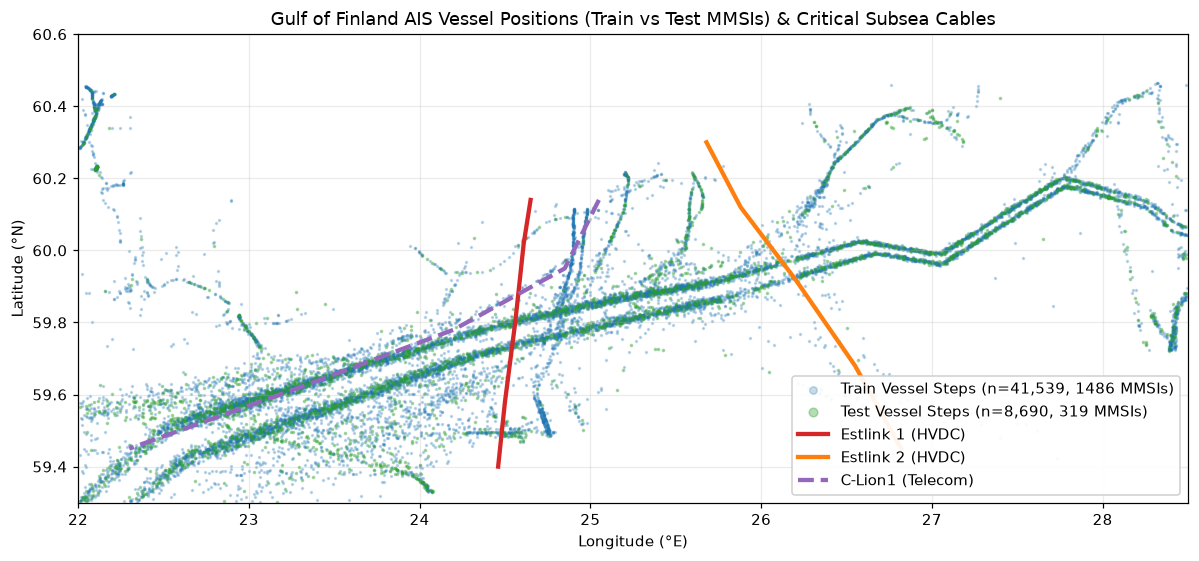

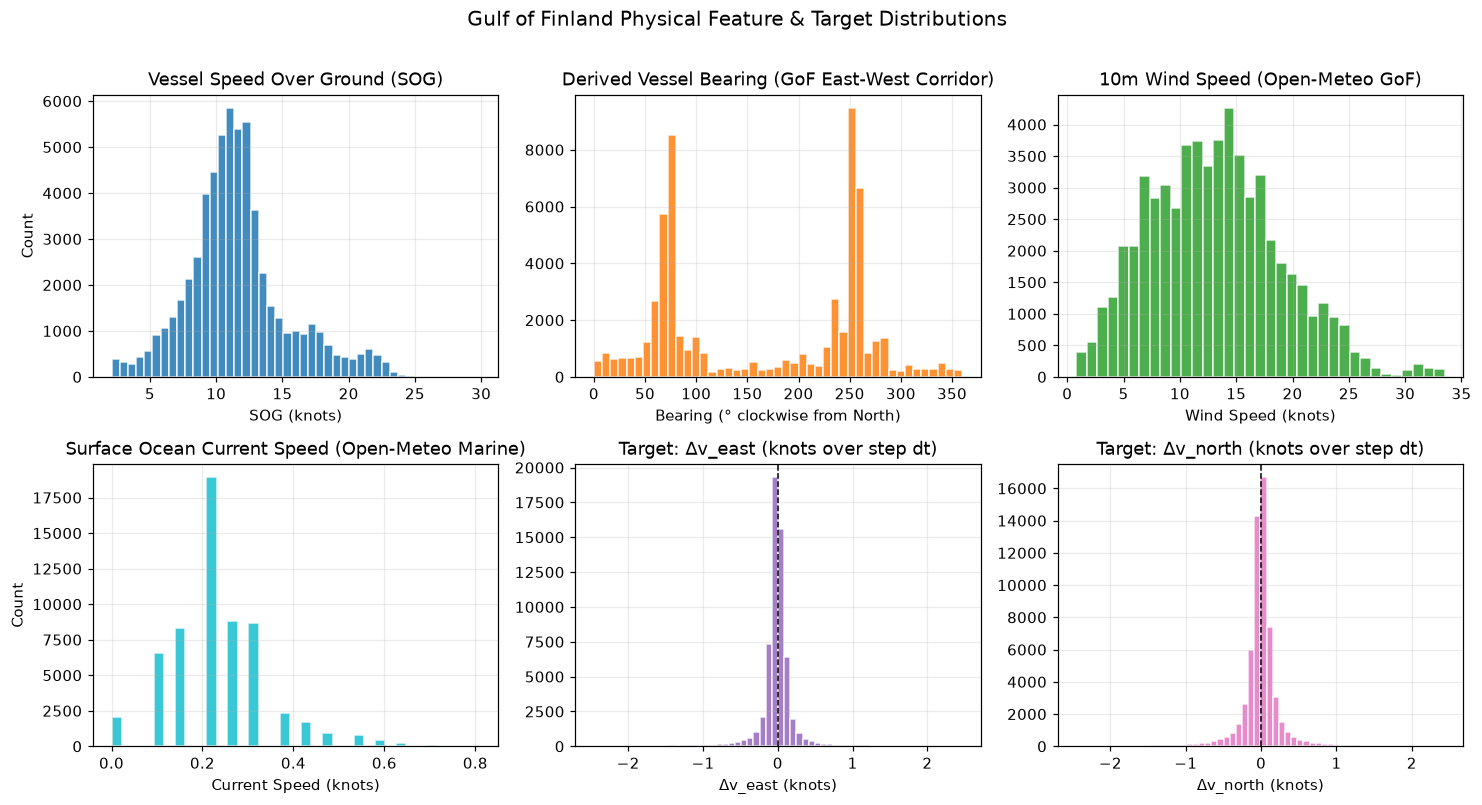

In [3]:
SUBSEA_CABLES: Dict[str, Dict[str, Any]] = {
    "Estlink 1 (HVDC)": {
        "coords": [(24.46, 59.40), (24.50, 59.58), (24.56, 59.80), (24.61, 60.02), (24.65, 60.14)],
        "color": "#d62728",
        "ls": "-",
    },
    "Estlink 2 (HVDC)": {
        "coords": [(26.82, 59.45), (26.55, 59.68), (26.20, 59.92), (25.88, 60.12), (25.68, 60.30)],
        "color": "#ff7f0e",
        "ls": "-",
    },
    "C-Lion1 (Telecom)": {
        "coords": [(25.05, 60.14), (24.85, 59.95), (24.20, 59.78), (23.30, 59.62), (22.30, 59.45)],
        "color": "#9467bd",
        "ls": "--",
    },
}


def plot_gof_tracks_and_cables(
    df_train: pd.DataFrame,
    df_test: pd.DataFrame,
    cables: Dict[str, Dict[str, Any]],
    n_train_vessels: int,
    n_test_vessels: int,
) -> None:
    """Plot Gulf of Finland Train vs Test vessel positions overlaid with subsea cables.

    Args:
        df_train: Training subset DataFrame.
        df_test: Testing subset DataFrame.
        cables: Mapping of subsea cable names to polyline coordinates and styling.
        n_train_vessels: Count of unique training MMSIs.
        n_test_vessels: Count of unique testing MMSIs.
    """
    fig, ax = plt.subplots(figsize=(11, 5.2))
    ax.scatter(
        df_train["lon"].values[::3], df_train["lat"].values[::3],
        s=1.5, alpha=0.25, c="#1f77b4",
        label=f"Train Vessel Steps (n={len(df_train):,}, {n_train_vessels} MMSIs)",
    )
    ax.scatter(
        df_test["lon"].values[::3], df_test["lat"].values[::3],
        s=2.0, alpha=0.35, c="#2ca02c",
        label=f"Test Vessel Steps (n={len(df_test):,}, {n_test_vessels} MMSIs)",
    )

    for name, meta in cables.items():
        xs = [p[0] for p in meta["coords"]]
        ys = [p[1] for p in meta["coords"]]
        ax.plot(xs, ys, color=meta["color"], linestyle=meta["ls"], linewidth=2.8, label=name)

    ax.set_xlim(22.0, 28.5)
    ax.set_ylim(59.3, 60.6)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.set_title("Gulf of Finland AIS Vessel Positions (Train vs Test MMSIs) & Critical Subsea Cables")
    ax.legend(loc="lower right", markerscale=4, framealpha=0.92)
    plt.tight_layout()
    plt.show()


def plot_feature_and_target_distributions(df_all: pd.DataFrame) -> None:
    """Plot histograms of SOG, derived bearing, wind speed, current speed, and target velocity deltas.

    Args:
        df_all: Combined Gulf of Finland consecutive-step DataFrame.
    """
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.2))

    axes[0, 0].hist(df_all["sog"], bins=45, color="#1f77b4", edgecolor="white", alpha=0.85)
    axes[0, 0].set_title("Vessel Speed Over Ground (SOG)")
    axes[0, 0].set_xlabel("SOG (knots)")
    axes[0, 0].set_ylabel("Count")

    axes[0, 1].hist(df_all["bearing_deg"], bins=45, color="#ff7f0e", edgecolor="white", alpha=0.85)
    axes[0, 1].set_title("Derived Vessel Bearing (GoF East-West Corridor)")
    axes[0, 1].set_xlabel("Bearing (° clockwise from North)")

    axes[0, 2].hist(df_all["wind_speed"], bins=35, color="#2ca02c", edgecolor="white", alpha=0.85)
    axes[0, 2].set_title("10m Wind Speed (Open-Meteo GoF)")
    axes[0, 2].set_xlabel("Wind Speed (knots)")

    axes[1, 0].hist(df_all["current_speed"], bins=35, color="#17becf", edgecolor="white", alpha=0.85)
    axes[1, 0].set_title("Surface Ocean Current Speed (Open-Meteo Marine)")
    axes[1, 0].set_xlabel("Current Speed (knots)")
    axes[1, 0].set_ylabel("Count")

    axes[1, 1].hist(df_all["dv_east"], bins=60, color="#9467bd", edgecolor="white", alpha=0.85)
    axes[1, 1].axvline(0.0, color="black", linestyle="--", linewidth=1)
    axes[1, 1].set_title("Target: Δv_east (knots over step dt)")
    axes[1, 1].set_xlabel("Δv_east (knots)")

    axes[1, 2].hist(df_all["dv_north"], bins=60, color="#e377c2", edgecolor="white", alpha=0.85)
    axes[1, 2].axvline(0.0, color="black", linestyle="--", linewidth=1)
    axes[1, 2].set_title("Target: Δv_north (knots over step dt)")
    axes[1, 2].set_xlabel("Δv_north (knots)")

    plt.suptitle("Gulf of Finland Physical Feature & Target Distributions", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()


plot_gof_tracks_and_cables(train_df, test_df, SUBSEA_CABLES, len(train_mmsis), len(test_mmsis))
plot_feature_and_target_distributions(pairs_df)

---
## 3. Model Architecture & Untrained Baseline (Epoch 0)

`ShipMotionGaussianMLP` (`14 -> 64 -> 64 -> 4`) maps standardized vessel kinematics, metocean forcing, causal prior acceleration, vessel maneuverability class, and shipping-lane flow residuals to Gaussian mean $(\mu_{\text{east}}, \mu_{\text{north}})$ and positive variance $(\sigma_{\text{east}}^2, \sigma_{\text{north}}^2)$.

Epoch 0 (Untrained) Validation GaussianNLLLoss: 6.0938


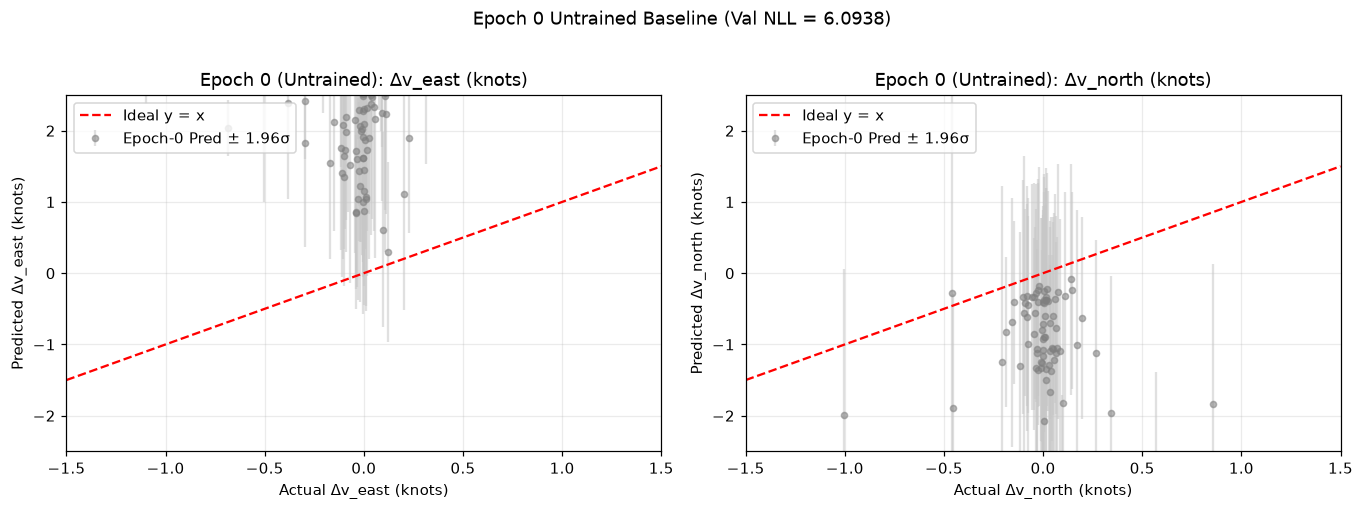

In [4]:
X_train_raw: np.ndarray = train_df[FEATURE_NAMES].values.astype(np.float32)
y_train_np: np.ndarray = train_df[TARGET_NAMES].values.astype(np.float32)
X_val_raw: np.ndarray = val_df[FEATURE_NAMES].values.astype(np.float32)
y_val_np: np.ndarray = val_df[TARGET_NAMES].values.astype(np.float32)
X_test_raw: np.ndarray = test_df[FEATURE_NAMES].values.astype(np.float32)
y_test_np: np.ndarray = test_df[TARGET_NAMES].values.astype(np.float32)

scaler_mean: np.ndarray = X_train_raw.mean(axis=0)
scaler_std: np.ndarray = X_train_raw.std(axis=0) + 1e-8
# Center flow features at 0.0 so OOD / flow-dropout (0.0, 0.0, 0.0) maps to exact 0.0 after standardization
scaler_mean[11:14] = 0.0
scaler_std[11] = float(np.sqrt(np.mean(X_train_raw[:, 11] ** 2)) + 1e-8)
scaler_std[12] = float(np.sqrt(np.mean(X_train_raw[:, 12] ** 2)) + 1e-8)
scaler_std[13] = 1.0

X_train_np: np.ndarray = (X_train_raw - scaler_mean) / scaler_std
X_val_np: np.ndarray = (X_val_raw - scaler_mean) / scaler_std
X_test_np: np.ndarray = (X_test_raw - scaler_mean) / scaler_std


class ShipMotionGaussianMLP(nn.Module):
    """Probabilistic 3-layer MLP (14 -> 64 -> 64 -> 4) predicting Gaussian (mu, var) of (dv_east, dv_north)."""

    def __init__(self, in_features: int = 14, hidden_dim: int = 64, eps: float = 1e-4) -> None:
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, 4)
        self.eps = eps
        self._init_weights()

    def _init_weights(self) -> None:
        set_seed(42)
        base_fc1 = nn.Linear(min(11, self.fc1.in_features), self.fc1.out_features)
        base_fc2 = nn.Linear(self.fc2.in_features, self.fc2.out_features)
        base_fc3 = nn.Linear(self.fc3.in_features, self.fc3.out_features)
        for layer in (base_fc1, base_fc2):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
        nn.init.kaiming_normal_(base_fc3.weight, nonlinearity="linear")
        nn.init.zeros_(base_fc3.bias)
        with torch.no_grad():
            self.fc1.weight.zero_()
            self.fc1.weight[:, :base_fc1.in_features].copy_(base_fc1.weight)
            self.fc1.bias.copy_(base_fc1.bias)
            self.fc2.weight.copy_(base_fc2.weight)
            self.fc2.bias.copy_(base_fc2.bias)
            self.fc3.weight.copy_(base_fc3.weight)
            self.fc3.bias.copy_(base_fc3.bias)

    def forward(self, x: Tensor) -> Tuple[Tensor, Tensor]:
        h = F.relu(self.fc1(x))
        h = F.relu(self.fc2(h))
        out = self.fc3(h)
        mu = out[:, :2]
        var = F.softplus(out[:, 2:], beta=1.0, threshold=20.0) + self.eps
        return mu, var


@torch.inference_mode()
def evaluate(
    model: nn.Module,
    dataloader: DataLoader,
    loss_fn: nn.Module,
    dev: torch.device,
) -> Tuple[float, Tensor, Tensor]:
    """Evaluate model Gaussian NLL loss and collect predictions across a DataLoader."""
    model.eval()
    total_loss = 0.0
    total_count = 0
    mu_batches: List[Tensor] = []
    var_batches: List[Tensor] = []

    for xb, yb in dataloader:
        xb = xb.to(dev)
        yb = yb.to(dev)
        mu, var = model(xb)
        loss = loss_fn(mu, yb, var)
        batch_n = xb.size(0)
        total_loss += loss.item() * batch_n
        total_count += batch_n
        mu_batches.append(mu.detach().cpu())
        var_batches.append(var.detach().cpu())

    return total_loss / max(total_count, 1), torch.cat(mu_batches, dim=0), torch.cat(var_batches, dim=0)


BATCH_SIZE: int = 512
set_seed(42)

train_dataset = TensorDataset(torch.from_numpy(X_train_np), torch.from_numpy(y_train_np))
val_dataset = TensorDataset(torch.from_numpy(X_val_np), torch.from_numpy(y_val_np))
test_dataset = TensorDataset(torch.from_numpy(X_test_np), torch.from_numpy(y_test_np))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

model = ShipMotionGaussianMLP(in_features=len(FEATURE_NAMES), hidden_dim=64, eps=1e-4).to(device)
loss_fn = nn.GaussianNLLLoss()

ep0_val_loss, mu_ep0_cpu, var_ep0_cpu = evaluate(model, val_loader, loss_fn, device)
mu_ep0_np = mu_ep0_cpu.numpy()
std_ep0_np = torch.sqrt(var_ep0_cpu).numpy()
print(f"Epoch 0 (Untrained) Validation GaussianNLLLoss: {ep0_val_loss:.4f}")

vis_n = 80
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
for dim_i, (ax, label) in enumerate(zip(axes, ["Δv_east (knots)", "Δv_north (knots)"])):
    ax.errorbar(
        y_val_np[:vis_n, dim_i],
        mu_ep0_np[:vis_n, dim_i],
        yerr=1.96 * std_ep0_np[:vis_n, dim_i],
        fmt="o", markersize=4, alpha=0.55, color="#7f7f7f", ecolor="#c7c7c7",
        label="Epoch-0 Pred ± 1.96σ",
    )
    ax.plot([-1.5, 1.5], [-1.5, 1.5], "r--", lw=1.5, label="Ideal y = x")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_xlabel(f"Actual {label}")
    ax.set_ylabel(f"Predicted {label}")
    ax.set_title(f"Epoch 0 (Untrained): {label}")
    ax.legend(loc="upper left")

plt.suptitle(f"Epoch 0 Untrained Baseline (Val NLL = {ep0_val_loss:.4f})", y=1.02)
plt.tight_layout()
plt.show()

---
## 4. Training Loop with 20% Flow Dropout

Train `ShipMotionGaussianMLP` (`14 -> 64 -> 64 -> 4`) with gradient clipping (`max_norm=1.0`) and **20% Flow Dropout** (randomly zeroing `(flow_dv_east, flow_dv_north, has_flow)` on 20% of training samples per epoch) so `v3` bends along Gulf of Finland shipping lanes (`has_flow = 1.0`) while preserving pure-kinematics generalization on unseen seas (`has_flow = 0.0`).

Epoch 01/35 | Train GaussianNLL (20% Flow Dropout): -1.1855 | Val GaussianNLL: -1.1191


Epoch 05/35 | Train GaussianNLL (20% Flow Dropout): -1.1898 | Val GaussianNLL: -1.1251


Epoch 10/35 | Train GaussianNLL (20% Flow Dropout): -1.1931 | Val GaussianNLL: -1.1270


Epoch 15/35 | Train GaussianNLL (20% Flow Dropout): -1.1946 | Val GaussianNLL: -1.1284


Epoch 20/35 | Train GaussianNLL (20% Flow Dropout): -1.1968 | Val GaussianNLL: -1.1285


Epoch 25/35 | Train GaussianNLL (20% Flow Dropout): -1.1965 | Val GaussianNLL: -1.1300


Epoch 30/35 | Train GaussianNLL (20% Flow Dropout): -1.1975 | Val GaussianNLL: -1.1304


Epoch 35/35 | Train GaussianNLL (20% Flow Dropout): -1.1982 | Val GaussianNLL: -1.1309

Finished 35 flow-aware epochs in 34.63s | Loaded best v3 checkpoint from epoch 35 (Val NLL = -1.1309)


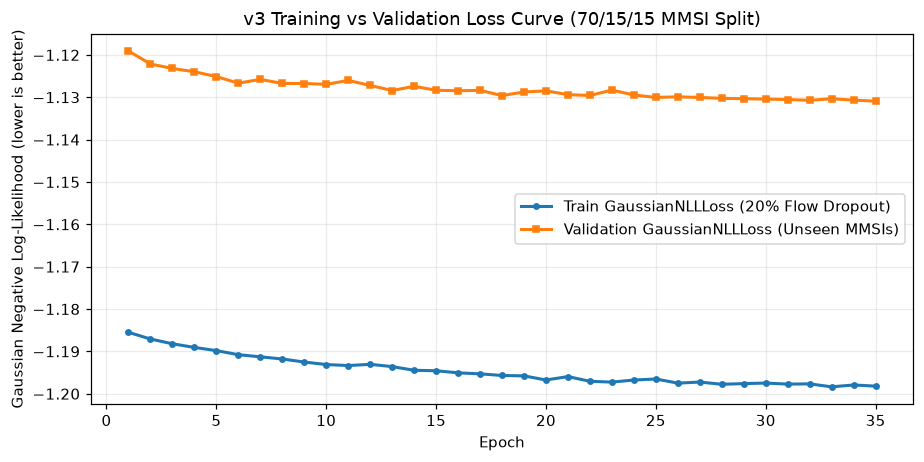

In [5]:
FLOW_DROPOUT_P: float = 0.20
EPOCHS: int = 35
LEARNING_RATE: float = 1e-3


def train_kinematic_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    loss_fn: nn.Module,
    optimizer: torch.optim.Optimizer,
    dev: torch.device,
    max_grad_norm: float = 1.0,
) -> float:
    """Run one pure-kinematic epoch (`flow_dv_east = flow_dv_north = has_flow = 0`)."""
    model.train()
    running_loss = 0.0
    total_samples = 0
    for xb, yb in dataloader:
        xb = xb.to(dev)
        yb = yb.to(dev)
        xb_nf = xb.clone()
        xb_nf[:, 11:14] = 0.0
        optimizer.zero_grad(set_to_none=True)
        mu_pred, var_pred = model(xb_nf)
        loss = loss_fn(mu_pred, yb, var_pred)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        optimizer.step()
        batch_n = xb.size(0)
        running_loss += loss.item() * batch_n
        total_samples += batch_n
    return running_loss / max(total_samples, 1)


def train_one_epoch(
    model: nn.Module,
    ref_kinematic_model: nn.Module,
    dataloader: DataLoader,
    loss_fn: nn.Module,
    optimizer: torch.optim.Optimizer,
    dev: torch.device,
    flow_dropout_p: float = FLOW_DROPOUT_P,
    max_grad_norm: float = 1.0,
) -> float:
    """Run one flow-aware training epoch with 20% Flow Dropout and OOD fallback consistency."""
    model.train()
    running_nll = 0.0
    total_samples = 0
    m0_e = float(scaler_mean[0])
    s0_e = float(scaler_std[0])
    m1_n = float(scaler_mean[1])
    s1_n = float(scaler_std[1])

    for xb, yb in dataloader:
        xb = xb.to(dev)
        yb = yb.to(dev)
        drop_mask = torch.rand(xb.size(0), device=dev) < flow_dropout_p
        xb_drop = xb.clone()
        if drop_mask.any():
            xb_drop[drop_mask, 11:14] = 0.0
        xb_nf = xb.clone()
        xb_nf[:, 11:14] = 0.0

        with torch.no_grad():
            mu_ref, var_ref = ref_kinematic_model(xb_nf)

        optimizer.zero_grad(set_to_none=True)
        mu_pred, var_pred = model(xb_drop)
        mu_nf, var_nf = model(xb_nf)

        ve_b = xb_drop[:, 0] * s0_e + m0_e
        vn_b = xb_drop[:, 1] * s1_n + m1_n
        sog_b = torch.clamp(torch.hypot(ve_b, vn_b), min=2.0)
        pred_sog = torch.hypot(ve_b + mu_pred[:, 0], vn_b + mu_pred[:, 1])
        act_sog = torch.hypot(ve_b + yb[:, 0], vn_b + yb[:, 1])
        spd_loss = F.mse_loss(pred_sog, act_sog)

        cross_dv = torch.abs(ve_b * yb[:, 1] - vn_b * yb[:, 0]) / sog_b
        is_turn_mse = (cross_dv > 0.08 * sog_b).float() * xb_drop[:, 13]
        is_turn_nll = (cross_dv > 0.18 * sog_b).float() * xb_drop[:, 13]
        vec_err = (yb[:, 0] - mu_pred[:, 0]) ** 2 + (yb[:, 1] - mu_pred[:, 1]) ** 2
        turn_mse = torch.mean((1.0 + 3.0 * is_turn_mse) * vec_err)
        nll_per = 0.25 * (
            torch.log(var_pred[:, 0]) + (yb[:, 0] - mu_pred[:, 0]) ** 2 / var_pred[:, 0] +
            torch.log(var_pred[:, 1]) + (yb[:, 1] - mu_pred[:, 1]) ** 2 / var_pred[:, 1]
        )
        nll_main = torch.mean((1.0 + 1.8 * is_turn_nll) * nll_per)
        ood_anchor = F.mse_loss(mu_nf, mu_ref) + 0.5 * F.mse_loss(torch.log(var_nf), torch.log(var_ref))

        loss = nll_main + 0.6 * turn_mse + 1.5 * spd_loss + 20.0 * ood_anchor
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        optimizer.step()

        batch_n = xb.size(0)
        running_nll += float(nll_per.detach().mean().item()) * batch_n
        total_samples += batch_n

    return running_nll / max(total_samples, 1)


t_start = time.time()

# Phase 1: Train pure-kinematic trunk (flow features zeroed) from scratch
set_seed(42)
optimizer_s1 = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler_s1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_s1, T_max=EPOCHS, eta_min=1e-4)
best_s1_val: float = float("inf")
best_s1_state: Dict[str, Tensor] = {}

for ep in range(1, EPOCHS + 1):
    _ = train_kinematic_epoch(model, train_loader, loss_fn, optimizer_s1, device, max_grad_norm=1.0)
    scheduler_s1.step()
    model.eval()
    vloss_s1 = 0.0
    vcnt_s1 = 0
    with torch.inference_mode():
        for xb, yb in val_loader:
            xb_nf = xb.to(device).clone()
            xb_nf[:, 11:14] = 0.0
            mu_v, var_v = model(xb_nf)
            vloss_s1 += loss_fn(mu_v, yb.to(device), var_v).item() * xb.size(0)
            vcnt_s1 += xb.size(0)
    vloss_s1 /= max(vcnt_s1, 1)
    if vloss_s1 < best_s1_val:
        best_s1_val = vloss_s1
        best_s1_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

ref_kinematic_model = ShipMotionGaussianMLP(in_features=len(FEATURE_NAMES), hidden_dim=64, eps=1e-4).to(device)
ref_kinematic_model.load_state_dict(best_s1_state)
ref_kinematic_model.eval()

# Phase 2: Flow-aware training with 20% Flow Dropout per epoch
model.load_state_dict(best_s1_state)
set_seed(42)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=5e-5)

epoch_history: List[int] = []
train_loss_history: List[float] = []
val_loss_history: List[float] = []
best_val_score: float = float("inf")

for epoch in range(1, EPOCHS + 1):
    epoch_train_loss = train_one_epoch(
        model,
        ref_kinematic_model,
        train_loader,
        loss_fn,
        optimizer,
        device,
        flow_dropout_p=FLOW_DROPOUT_P,
        max_grad_norm=1.0,
    )
    scheduler.step()
    epoch_val_loss, mu_val_t, _ = evaluate(model, val_loader, loss_fn, device)
    val_mse = float(F.mse_loss(mu_val_t, torch.from_numpy(y_val_np)).item())
    val_score = epoch_val_loss + 0.5 * val_mse

    epoch_history.append(epoch)
    train_loss_history.append(epoch_train_loss)
    val_loss_history.append(epoch_val_loss)

    if val_score < best_val_score:
        best_val_score = val_score
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": epoch_train_loss,
                "val_loss": epoch_val_loss,
                "feature_names": FEATURE_NAMES,
                "target_names": TARGET_NAMES,
                "scaler_mean": scaler_mean.tolist(),
                "scaler_std": scaler_std.tolist(),
            },
            CHECKPOINT_PT_PATH,
        )

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(
            f"Epoch {epoch:02d}/{EPOCHS} | Train GaussianNLL (20% Flow Dropout): {epoch_train_loss:+.4f} "
            f"| Val GaussianNLL: {epoch_val_loss:+.4f}"
        )

checkpoint = torch.load(CHECKPOINT_PT_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
print(
    f"\nFinished {EPOCHS} flow-aware epochs in {time.time() - t_start:.2f}s | "
    f"Loaded best v3 checkpoint from epoch {checkpoint["epoch"]} (Val NLL = {checkpoint["val_loss"]:+.4f})"
)

fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(epoch_history, train_loss_history, marker="o", markersize=3.5, lw=2, color="#1f77b4", label="Train GaussianNLLLoss (20% Flow Dropout)")
ax.plot(epoch_history, val_loss_history, marker="s", markersize=3.5, lw=2, color="#ff7f0e", label="Validation GaussianNLLLoss (Unseen MMSIs)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Gaussian Negative Log-Likelihood (lower is better)")
ax.set_title("v3 Training vs Validation Loss Curve (70/15/15 MMSI Split)")
ax.legend()
plt.tight_layout()
plt.show()

---
## 5. Held-Out Test Evaluation, Anchor-Drag Demo & Pure-Python Export

Evaluate the selected `v3` checkpoint on untouched **Test** vessels (overall and curved-lane turns $|\Delta\text{bearing}| \ge 10^\circ$), simulate a self-consistent anchor-drag slowdown across a subsea cable corridor ($2\text{D Radial } Z > 2.45\sigma$), persist `data/eval_data/gof_2024_test_pairs.json`, and export `weights/ship_motion_mlp.json` with `< 1e-5` parity against `mlp_infer.py`.

=== Held-Out Test Set Evaluation (Unseen MMSIs, 14-Feature v3) ===
  Test Gaussian NLL:             -1.2371
  Test Speed RMSE:               0.19022 knots
  Test Bearing RMSE:             2.06098 degrees
  Test Vector Velocity RMSE:     0.35264 knots
  Empirical 95% CI (Δv_east):    95.85%
  Empirical 95% CI (Δv_north):   95.96%
  Empirical 95% CI (Marginal):   95.90%  (Target: 90-96%)
  Empirical 95% CI (2D Radial):  94.94%  (radial_z <= 2.448, Target: 90-96%)
  Curved-Lane Turns (|Δbrg|>=10°, has_flow=1, n=74):
    Turn Bearing RMSE:           v3 = 15.0288° vs Persistence = 15.9455°
    Turn Vector Velocity RMSE:   v3 = 1.6364 kn vs Persistence = 1.7655 kn


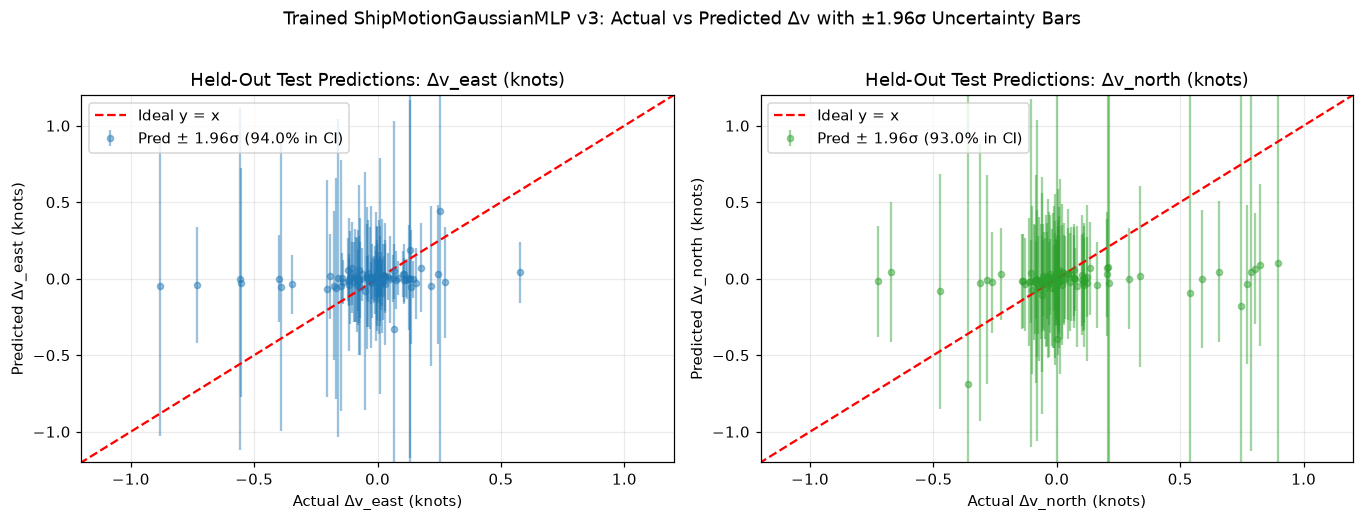

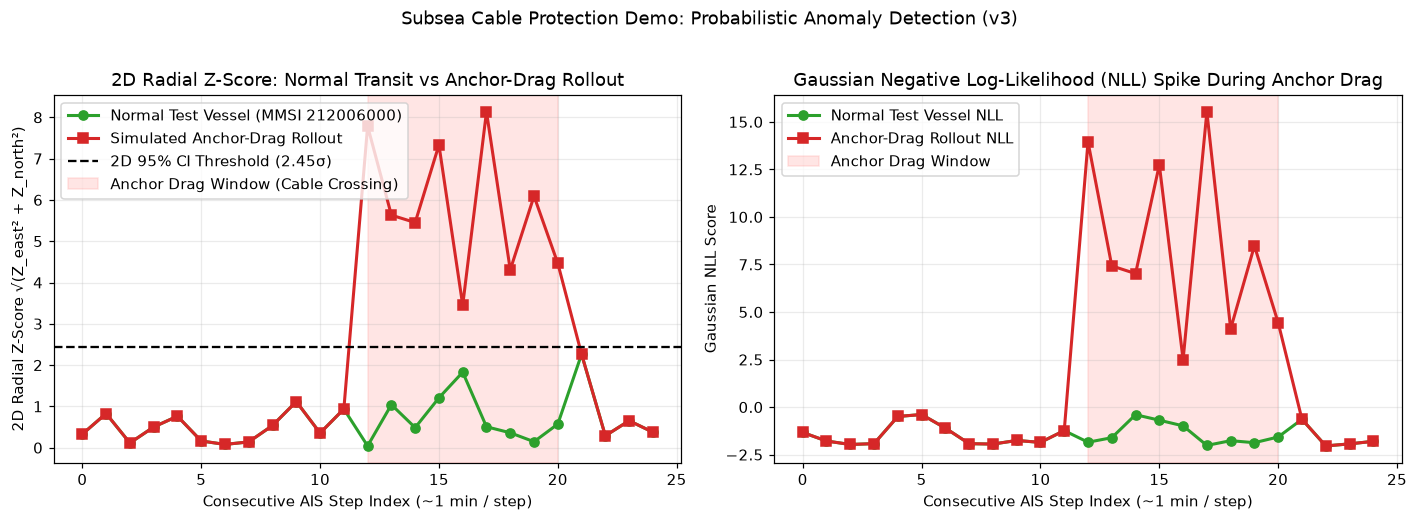

In [6]:
def compute_z_and_nll(
    dv_arr: np.ndarray,
    mu_arr: np.ndarray,
    var_arr: np.ndarray,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Compute component-wise max |Z|, 2D radial Z-score, and Gaussian NLL for arrays of shape `(N, 2)`."""
    var_clamped = np.maximum(var_arr, 1e-12)
    std_arr = np.sqrt(var_clamped)
    ze = (dv_arr[:, 0] - mu_arr[:, 0]) / std_arr[:, 0]
    zn = (dv_arr[:, 1] - mu_arr[:, 1]) / std_arr[:, 1]
    max_abs_z = np.maximum(np.abs(ze), np.abs(zn))
    radial_z = np.hypot(ze, zn)
    nll = 0.25 * (np.log(var_clamped[:, 0]) + ze ** 2 + np.log(var_clamped[:, 1]) + zn ** 2)
    return max_abs_z, radial_z, nll


test_nll_loss, mu_test_t, var_test_t = evaluate(model, test_loader, loss_fn, device)
mu_test = mu_test_t.numpy()
var_test = var_test_t.numpy()
std_test = np.sqrt(var_test)

pred_v_east_next = test_df["v_east"].values + mu_test[:, 0]
pred_v_north_next = test_df["v_north"].values + mu_test[:, 1]
pred_sog_next = np.hypot(pred_v_east_next, pred_v_north_next)
pred_bearing_next_deg = np.degrees(np.arctan2(pred_v_east_next, pred_v_north_next) % (2.0 * np.pi))

actual_sog_next = test_df["sog_next"].values
actual_bearing_next_deg = test_df["bearing_next_deg"].values

speed_rmse_kn = float(np.sqrt(np.mean((pred_sog_next - actual_sog_next) ** 2)))
bearing_diff_deg = (pred_bearing_next_deg - actual_bearing_next_deg + 180.0) % 360.0 - 180.0
bearing_rmse_deg = float(np.sqrt(np.mean(bearing_diff_deg ** 2)))
vec_rmse_kn = float(np.sqrt(np.mean((y_test_np[:, 0] - mu_test[:, 0]) ** 2 + (y_test_np[:, 1] - mu_test[:, 1]) ** 2)))

z_east = (y_test_np[:, 0] - mu_test[:, 0]) / std_test[:, 0]
z_north = (y_test_np[:, 1] - mu_test[:, 1]) / std_test[:, 1]
radial_z_test = np.hypot(z_east, z_north)

cov_east_95 = float(np.mean(np.abs(z_east) <= 1.96) * 100.0)
cov_north_95 = float(np.mean(np.abs(z_north) <= 1.96) * 100.0)
cov_marginal_95 = 0.5 * (cov_east_95 + cov_north_95)
cov_joint2d_95 = float(np.mean(radial_z_test <= RADIAL_Z_95CI) * 100.0)

actual_turn_deg = np.abs((test_df["bearing_next_deg"].values - test_df["bearing_deg"].values + 180.0) % 360.0 - 180.0)
turn_mask = (actual_turn_deg >= 10.0) & (test_df["has_flow"].values == 1.0)
pers_brg_diff = (test_df["bearing_deg"].values - actual_bearing_next_deg + 180.0) % 360.0 - 180.0
turn_brg_rmse = float(np.sqrt(np.mean(bearing_diff_deg[turn_mask] ** 2)))
turn_pers_brg_rmse = float(np.sqrt(np.mean(pers_brg_diff[turn_mask] ** 2)))
turn_vec_rmse = float(np.sqrt(np.mean((y_test_np[turn_mask, 0] - mu_test[turn_mask, 0]) ** 2 + (y_test_np[turn_mask, 1] - mu_test[turn_mask, 1]) ** 2)))
turn_pers_vec_rmse = float(np.sqrt(np.mean(y_test_np[turn_mask, 0] ** 2 + y_test_np[turn_mask, 1] ** 2)))

print("=== Held-Out Test Set Evaluation (Unseen MMSIs, 14-Feature v3) ===")
print(f"  Test Gaussian NLL:             {test_nll_loss:+.4f}")
print(f"  Test Speed RMSE:               {speed_rmse_kn:.5f} knots")
print(f"  Test Bearing RMSE:             {bearing_rmse_deg:.5f} degrees")
print(f"  Test Vector Velocity RMSE:     {vec_rmse_kn:.5f} knots")
print(f"  Empirical 95% CI (Δv_east):    {cov_east_95:.2f}%")
print(f"  Empirical 95% CI (Δv_north):   {cov_north_95:.2f}%")
print(f"  Empirical 95% CI (Marginal):   {cov_marginal_95:.2f}%  (Target: 90-96%)")
print(f"  Empirical 95% CI (2D Radial):  {cov_joint2d_95:.2f}%  (radial_z <= {RADIAL_Z_95CI:.3f}, Target: 90-96%)")
print(f"  Curved-Lane Turns (|Δbrg|>=10°, has_flow=1, n={int(turn_mask.sum())}):")
print(f"    Turn Bearing RMSE:           v3 = {turn_brg_rmse:.4f}° vs Persistence = {turn_pers_brg_rmse:.4f}°")
print(f"    Turn Vector Velocity RMSE:   v3 = {turn_vec_rmse:.4f} kn vs Persistence = {turn_pers_vec_rmse:.4f} kn")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for dim_i, (ax, label, col) in enumerate(zip(axes, ["Δv_east (knots)", "Δv_north (knots)"], ["#1f77b4", "#2ca02c"])):
    idx_sub = np.argsort(y_test_np[:100, dim_i])
    actual_sub = y_test_np[:100, dim_i][idx_sub]
    pred_sub = mu_test[:100, dim_i][idx_sub]
    ci_sub = 1.96 * std_test[:100, dim_i][idx_sub]
    inside = np.abs(actual_sub - pred_sub) <= ci_sub

    ax.errorbar(
        actual_sub, pred_sub, yerr=ci_sub,
        fmt="o", markersize=4, color=col, ecolor=col, alpha=0.45,
        label=f"Pred ± 1.96σ ({inside.mean()*100:.1f}% in CI)",
    )
    ax.plot([-1.5, 1.5], [-1.5, 1.5], "r--", lw=1.5, label="Ideal y = x")
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_xlabel(f"Actual {label}")
    ax.set_ylabel(f"Predicted {label}")
    ax.set_title(f"Held-Out Test Predictions: {label}")
    ax.legend(loc="upper left")

plt.suptitle("Trained ShipMotionGaussianMLP v3: Actual vs Predicted Δv with ±1.96σ Uncertainty Bars", y=1.02)
plt.tight_layout()
plt.show()

# Self-consistent anchor-drag trajectory rollout on a held-out Test vessel
test_mmsi_counts = test_df.groupby("mmsi").size()
demo_mmsi = int(test_mmsi_counts[test_mmsi_counts >= 30].index[0])
track_df = test_df[test_df["mmsi"] == demo_mmsi].iloc[:25].reset_index(drop=True)

X_track_norm = torch.from_numpy(
    (track_df[FEATURE_NAMES].values.astype(np.float32) - scaler_mean) / scaler_std
).to(device)
model.eval()
with torch.inference_mode():
    mu_tr_t, var_tr_t = model(X_track_norm)
    mu_tr = mu_tr_t.detach().cpu().numpy()
    var_tr = var_tr_t.detach().cpu().numpy()

actual_dv_tr = track_df[TARGET_NAMES].values.astype(np.float64)
_, norm_rad_z, norm_nll = compute_z_and_nll(actual_dv_tr, mu_tr, var_tr)

# Roll state forward self-consistently during anchor drag (steps 12..20)
drag_mu_list: List[np.ndarray] = []
drag_var_list: List[np.ndarray] = []
drag_dv_list: List[np.ndarray] = []

ve_curr = float(track_df.loc[0, "v_east"])
vn_curr = float(track_df.loc[0, "v_north"])
prev_dve_curr = float(track_df.loc[0, "prev_dv_east"])
prev_dvn_curr = float(track_df.loc[0, "prev_dv_north"])

with torch.inference_mode():
    for step_i in range(len(track_df)):
        row_i = track_df.loc[step_i]
        if step_i < 12 or step_i > 20:
            ve_curr = float(row_i["v_east"])
            vn_curr = float(row_i["v_north"])
            prev_dve_curr = float(row_i["prev_dv_east"])
            prev_dvn_curr = float(row_i["prev_dv_north"])

        sog_curr = max(math.hypot(ve_curr, vn_curr), 2.5)
        brg_curr = math.atan2(ve_curr, vn_curr) % (2.0 * np.pi)
        wind_to_rad = math.radians((float(row_i["wind_dir_from"]) + 180.0) % 360.0)
        curr_to_rad = math.radians(float(row_i["current_dir_to"]) % 360.0)
        w_spd = float(row_i["wind_speed"])
        c_spd = float(row_i["current_speed"])
        dt_val = float(row_i["dt"])
        is_man_val = float(row_i["is_maneuver_vessel"])
        flow_dve_step, flow_dvn_step, has_flow_step = mlp_infer.lookup_flow(
            float(row_i["lat"]),
            float(row_i["lon"]),
            ve_curr,
            vn_curr,
            {"flow_field": flow_field_dict},
        )

        feat_step = np.array([
            ve_curr,
            vn_curr,
            sog_curr,
            dt_val,
            w_spd * math.cos(wind_to_rad - brg_curr),
            w_spd * math.sin(wind_to_rad - brg_curr),
            c_spd * math.cos(curr_to_rad - brg_curr),
            c_spd * math.sin(curr_to_rad - brg_curr),
            prev_dve_curr,
            prev_dvn_curr,
            is_man_val,
            flow_dve_step,
            flow_dvn_step,
            has_flow_step,
        ], dtype=np.float32)

        x_step_t = torch.from_numpy((feat_step - scaler_mean) / scaler_std).unsqueeze(0).to(device)
        mu_s, var_s = model(x_step_t)
        drag_mu_list.append(mu_s.squeeze(0).detach().cpu().numpy())
        drag_var_list.append(var_s.squeeze(0).detach().cpu().numpy())

        dve_step = float(row_i["dv_east"])
        dvn_step = float(row_i["dv_north"])
        if 12 <= step_i <= 20:
            along_drop = -2.2 if step_i in (12, 13, 14) else -1.5
            cross_drift = 1.3 if (step_i % 2 == 0) else -1.2
            dve_step += along_drop * math.sin(brg_curr) + cross_drift * math.cos(brg_curr)
            dvn_step += along_drop * math.cos(brg_curr) - cross_drift * math.sin(brg_curr)
            ve_next = ve_curr + 0.35 * dve_step
            vn_next = vn_curr + 0.35 * dvn_step
            spd_next = math.hypot(ve_next, vn_next)
            if spd_next < 3.5:
                scale = 3.5 / max(spd_next, 1e-6)
                ve_next *= scale
                vn_next *= scale
            prev_dve_curr = ve_next - ve_curr
            prev_dvn_curr = vn_next - vn_curr
            ve_curr, vn_curr = ve_next, vn_next

        drag_dv_list.append(np.array([dve_step, dvn_step], dtype=np.float64))

drag_mu_arr = np.vstack(drag_mu_list)
drag_var_arr = np.vstack(drag_var_list)
drag_dv_arr = np.vstack(drag_dv_list)
_, drag_rad_z, drag_nll = compute_z_and_nll(drag_dv_arr, drag_mu_arr, drag_var_arr)

steps = np.arange(len(track_df))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].plot(steps, norm_rad_z, "o-", color="#2ca02c", lw=2, label=f"Normal Test Vessel (MMSI {demo_mmsi})")
axes[0].plot(steps, drag_rad_z, "s-", color="#d62728", lw=2, label="Simulated Anchor-Drag Rollout")
axes[0].axhline(RADIAL_Z_95CI, color="black", linestyle="--", lw=1.5, label=f"2D 95% CI Threshold ({RADIAL_Z_95CI:.2f}σ)")
axes[0].axvspan(12, 20, color="#ff9896", alpha=0.25, label="Anchor Drag Window (Cable Crossing)")
axes[0].set_xlabel("Consecutive AIS Step Index (~1 min / step)")
axes[0].set_ylabel("2D Radial Z-Score √(Z_east² + Z_north²)")
axes[0].set_title("2D Radial Z-Score: Normal Transit vs Anchor-Drag Rollout")
axes[0].legend(loc="upper left")

axes[1].plot(steps, norm_nll, "o-", color="#2ca02c", lw=2, label="Normal Test Vessel NLL")
axes[1].plot(steps, drag_nll, "s-", color="#d62728", lw=2, label="Anchor-Drag Rollout NLL")
axes[1].axvspan(12, 20, color="#ff9896", alpha=0.25, label="Anchor Drag Window")
axes[1].set_xlabel("Consecutive AIS Step Index (~1 min / step)")
axes[1].set_ylabel("Gaussian NLL Score")
axes[1].set_title("Gaussian Negative Log-Likelihood (NLL) Spike During Anchor Drag")
axes[1].legend(loc="upper left")

plt.suptitle("Subsea Cable Protection Demo: Probabilistic Anomaly Detection (v3)", y=1.02)
plt.tight_layout()
plt.show()

In [7]:
def export_weights_to_json(
    trained_model: ShipMotionGaussianMLP,
    json_path: str,
    mean_vec: np.ndarray,
    std_vec: np.ndarray,
    metrics_dict: Dict[str, Any],
    check_vectors: List[Dict[str, Any]],
    flow_field_payload: Dict[str, Any],
) -> None:
    """Export trained MLP parameters, feature scaler, flow field, and reference test vectors to compact JSON."""
    state = {k: v.detach().cpu() for k, v in trained_model.state_dict().items()}
    export_payload = {
        "model_name": "ShipMotionGaussianMLP",
        "architecture": f"{len(FEATURE_NAMES)} -> 64 -> 64 -> 4 (ReLU + softplus var)",
        "feature_names": FEATURE_NAMES,
        "target_names": TARGET_NAMES,
        "eps": float(trained_model.eps),
        "softplus_threshold": 20.0,
        "radial_z_95ci": RADIAL_Z_95CI,
        "scaler": {
            "mean": [float(x) for x in mean_vec],
            "std": [float(x) for x in std_vec],
        },
        "layers": [
            {
                "name": "fc1",
                "weight": state["fc1.weight"].tolist(),
                "bias": state["fc1.bias"].tolist(),
                "activation": "relu",
            },
            {
                "name": "fc2",
                "weight": state["fc2.weight"].tolist(),
                "bias": state["fc2.bias"].tolist(),
                "activation": "relu",
            },
            {
                "name": "fc3",
                "weight": state["fc3.weight"].tolist(),
                "bias": state["fc3.bias"].tolist(),
                "activation": "linear",
            },
        ],
        "flow_field": flow_field_payload,
        "metrics": metrics_dict,
        "self_check_vectors": check_vectors,
    }
    with open(json_path, "w", encoding="utf-8") as fh:
        json.dump(export_payload, fh, separators=(",", ":"))


# Persist held-out 2024 GoF test pairs (including lat, lon, and flow features) for standalone benchmark evaluation
gof_test_export_cols = [
    "mmsi", "timestamp", "hour_ts", "lat", "lon", "sog", "sog_next",
    "bearing_rad", "bearing_deg", "bearing_next_deg",
    "v_east", "v_north", "v_east_next", "v_north_next", "dt",
    "wind_speed", "current_speed",
    "wind_along", "wind_cross", "current_along", "current_cross",
    "prev_dv_east", "prev_dv_north", "is_maneuver_vessel",
    "flow_dv_east", "flow_dv_north", "has_flow",
    "dv_east", "dv_north",
]
with open(GOF_TEST_PAIRS_PATH, "w", encoding="utf-8") as fh:
    json.dump(
        {
            "n_pairs": int(len(test_df)),
            "n_mmsis": int(len(test_mmsis)),
            "pairs": test_df[gof_test_export_cols].to_dict(orient="records"),
        },
        fh,
    )
print(f"Persisted held-out GoF test pairs to: {os.path.abspath(GOF_TEST_PAIRS_PATH)} ({len(test_df):,} steps)")

model.eval()
with torch.inference_mode():
    x_ref_dev = torch.from_numpy(X_test_np[:500]).to(device)
    mu_dev_ref, var_dev_ref = model(x_ref_dev)
    mu_cpu_ref = mu_dev_ref.detach().cpu()
    var_cpu_ref = var_dev_ref.detach().cpu()
    std_cpu_ref = torch.sqrt(var_cpu_ref)

y_test_cpu = torch.from_numpy(y_test_np[:500])
self_check_vectors: List[Dict[str, Any]] = []
for i in range(10):
    raw_feats = [float(x) for x in X_test_raw[i]]
    actual_dv = [float(y_test_np[i, 0]), float(y_test_np[i, 1])]
    exp_pred = [
        float(mu_cpu_ref[i, 0].item()),
        float(mu_cpu_ref[i, 1].item()),
        float(std_cpu_ref[i, 0].item()),
        float(std_cpu_ref[i, 1].item()),
    ]
    single_nll = float(
        loss_fn(
            mu_cpu_ref[i : i + 1],
            y_test_cpu[i : i + 1],
            var_cpu_ref[i : i + 1],
        ).item()
    )
    self_check_vectors.append({
        "features": raw_feats,
        "actual_dv": actual_dv,
        "expected_pred": exp_pred,
        "expected_nll": single_nll,
    })

summary_metrics: Dict[str, Any] = {
    "val_nll": round(float(checkpoint["val_loss"]), 5),
    "test_nll": round(float(test_nll_loss), 5),
    "test_speed_rmse_kn": round(speed_rmse_kn, 5),
    "test_bearing_rmse_deg": round(bearing_rmse_deg, 5),
    "test_vec_rmse_kn": round(vec_rmse_kn, 5),
    "test_turn_bearing_rmse_deg": round(turn_brg_rmse, 4),
    "test_turn_vec_rmse_kn": round(turn_vec_rmse, 4),
    "empirical_95ci_east_pct": round(cov_east_95, 2),
    "empirical_95ci_north_pct": round(cov_north_95, 2),
    "empirical_95ci_marginal_pct": round(cov_marginal_95, 2),
    "empirical_95ci_joint2d_pct": round(cov_joint2d_95, 2),
    "flow_cells": int(len(flow_field_dict["cells"])),
    "train_rows": int(len(train_df)),
    "val_rows": int(len(val_df)),
    "test_rows": int(len(test_df)),
    "train_mmsis": int(len(train_mmsis)),
    "val_mmsis": int(len(val_mmsis)),
    "test_mmsis": int(len(test_mmsis)),
}

export_weights_to_json(
    model,
    WEIGHTS_JSON_PATH,
    scaler_mean,
    scaler_std,
    summary_metrics,
    self_check_vectors,
    flow_field_dict,
)
print(f"Model remained on device:       {next(model.parameters()).device}")
print(f"Saved PyTorch v3 checkpoint to: {os.path.abspath(CHECKPOINT_PT_PATH)} ({os.path.getsize(CHECKPOINT_PT_PATH):,} bytes)")
print(f"Exported v3 weights JSON to:    {os.path.abspath(WEIGHTS_JSON_PATH)} ({os.path.getsize(WEIGHTS_JSON_PATH):,} bytes / {os.path.getsize(WEIGHTS_JSON_PATH)/1024:.1f} KB)")

loaded_json_model = mlp_infer.load_model(WEIGHTS_JSON_PATH, refresh=True)
max_pred_diff = 0.0
max_nll_diff = 0.0

for i in range(500):
    feats_i = [float(x) for x in X_test_raw[i]]
    py_pred = mlp_infer.predict(feats_i, model_data=loaded_json_model)
    pt_pred = (
        float(mu_cpu_ref[i, 0].item()),
        float(mu_cpu_ref[i, 1].item()),
        float(std_cpu_ref[i, 0].item()),
        float(std_cpu_ref[i, 1].item()),
    )
    diff = max(abs(a - b) for a, b in zip(py_pred, pt_pred))
    if diff > max_pred_diff:
        max_pred_diff = diff

    _, _, _, py_nll, _ = mlp_infer.anomaly_score(
        float(y_test_np[i, 0]), float(y_test_np[i, 1]), py_pred
    )
    pt_nll = float(
        loss_fn(
            mu_cpu_ref[i : i + 1],
            y_test_cpu[i : i + 1],
            var_cpu_ref[i : i + 1],
        ).item()
    )
    nll_diff = abs(py_nll - pt_nll)
    if nll_diff > max_nll_diff:
        max_nll_diff = nll_diff

print(f"Max abs diff (PyTorch vs pure-Python mlp_infer.predict):       {max_pred_diff:.3e}")
print(f"Max abs diff (PyTorch vs pure-Python mlp_infer.anomaly_score): {max_nll_diff:.3e}")
assert max_pred_diff < 1e-5, f"Parity check failed: {max_pred_diff} >= 1e-5"
assert max_nll_diff < 1e-5, f"NLL parity check failed: {max_nll_diff} >= 1e-5"
print("SUCCESS: Pure-Python mlp_infer.py matches PyTorch v3 within < 1e-5!")

Persisted held-out GoF test pairs to: /Users/binhlien/Projects/hackathons/KAIKU/ML/data/eval_data/gof_2024_test_pairs.json (8,690 steps)
Model remained on device:       mps:0
Saved PyTorch v3 checkpoint to: /Users/binhlien/Projects/hackathons/KAIKU/ML/weights/ship_motion_mlp.pt (73,189 bytes)
Exported v3 weights JSON to:    /Users/binhlien/Projects/hackathons/KAIKU/ML/weights/ship_motion_mlp.json (395,409 bytes / 386.1 KB)
Max abs diff (PyTorch vs pure-Python mlp_infer.predict):       4.742e-07
Max abs diff (PyTorch vs pure-Python mlp_infer.anomaly_score): 9.492e-06
SUCCESS: Pure-Python mlp_infer.py matches PyTorch v3 within < 1e-5!
